# PhishLens — Exploratory Data Analysis

Before training anything, we look at the data. Goals:

1. Confirm the dataset is balanced and see where it came from.
2. Find **real differences** between phishing and legit URLs (these become our features).
3. Catch **collection bias** — differences caused by *how we gathered data*, not by phishing itself.

All measurements use `model_input(url)`: the URL **without** `http(s)://` and `www.`, exactly what
the models will see.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from phishlens.urls import hostname, model_input

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "docs" / "images"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical pair (colour-blind safe): legit = blue, phishing = orange
COLORS = {"legit": "#2a78d6", "phishing": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": TEXT,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load and overview

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "dataset.csv")
df["cls"] = df["label"].map({0: "legit", 1: "phishing"})
df["mi"] = df["url"].map(model_input)  # what the models see
df["host"] = df["url"].map(hostname)

print(f"{len(df):,} URLs, {df['domain'].nunique():,} distinct websites")
df.groupby(["cls", "source"]).size().rename("urls").to_frame()

40,000 URLs, 19,115 distinct websites


urls
cls      source                  
legit    tranco_homepage     2185
         tranco_link        17815
phishing openphish            279
         phishing_database  19721

Balanced 50/50. Legit URLs come from ~3.6k crawled websites (several URLs each); phishing URLs
come from ~15.5k websites (about one each). That is why we will **split train/test by website**
in Phase 3.

## 2. URL length

           25%   50%   75%  mean
cls                             
legit     22.0  32.0  48.0  41.0
phishing  28.0  43.0  73.0  65.5


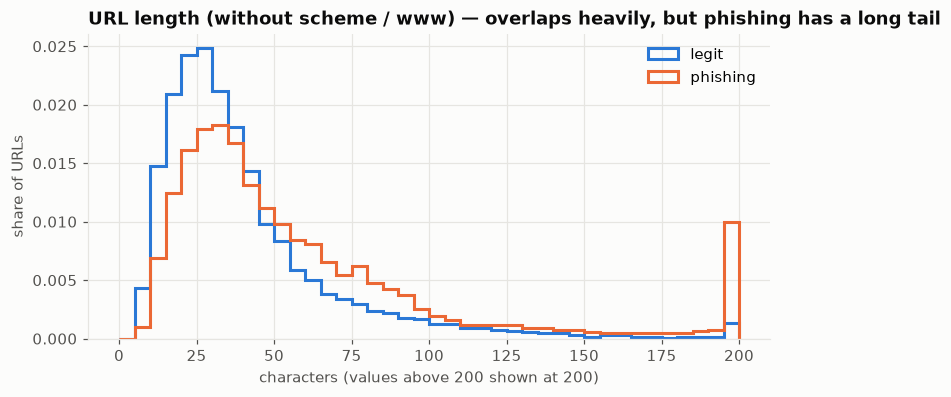

In [3]:
df["length"] = df["mi"].str.len()
print(df.groupby("cls")["length"].describe()[["25%", "50%", "75%", "mean"]].round(1))

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 205, 5)
for cls in ["legit", "phishing"]:
    vals = df.loc[df["cls"] == cls, "length"].clip(upper=200)
    ax.hist(
        vals, bins=bins, histtype="step", linewidth=2, color=COLORS[cls], label=cls, density=True
    )
ax.set_title("URL length (without scheme / www) — overlaps heavily, but phishing has a long tail")
ax.set_xlabel("characters (values above 200 shown at 200)")
ax.set_ylabel("share of URLs")
ax.legend(loc="upper right")
save(fig, "length")
plt.show()

**Reading:** most URLs of both classes are 15–60 characters, so length alone cannot separate them
(good — no shortcut). Phishing has a much longer tail (fake folders, tracking tokens).
Feature value: **useful hint, not decisive**.

## 3. Top-level domains (TLDs)

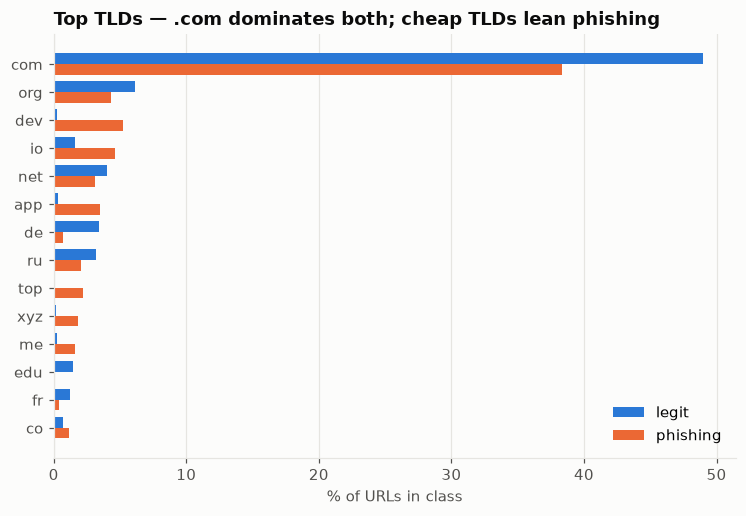

cls,legit,phishing
tld,,
com,49.00,38.34
org,6.16,4.35
dev,0.28,5.20
io,1.58,4.60
net,4.01,3.15
app,0.34,3.50
de,3.42,0.70
ru,3.16,2.08
top,0.10,2.20


In [4]:
import tldextract

_ext = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=False)
df["tld"] = df["host"].map(lambda h: _ext(h).suffix or "(ip)")

share = df.groupby("cls")["tld"].value_counts(normalize=True).mul(100).unstack(0).fillna(0)
top = share.max(axis=1).sort_values(ascending=False).head(14).index
share = share.loc[top[::-1]]

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(share))
h = 0.38
ax.barh(y + h / 2, share["legit"], height=h, color=COLORS["legit"], label="legit")
ax.barh(y - h / 2, share["phishing"], height=h, color=COLORS["phishing"], label="phishing")
ax.set_yticks(y, share.index)
ax.set_xlabel("% of URLs in class")
ax.set_title("Top TLDs — .com dominates both; cheap TLDs lean phishing")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "tlds")
plt.show()
share.iloc[::-1].round(2)

**Reading:** look for TLDs where the orange bar is much longer than the blue one — those support
the `suspicious_tld` feature. Country TLDs on the legit side reflect the crawled sites' locations.

## 4. Suspicious words

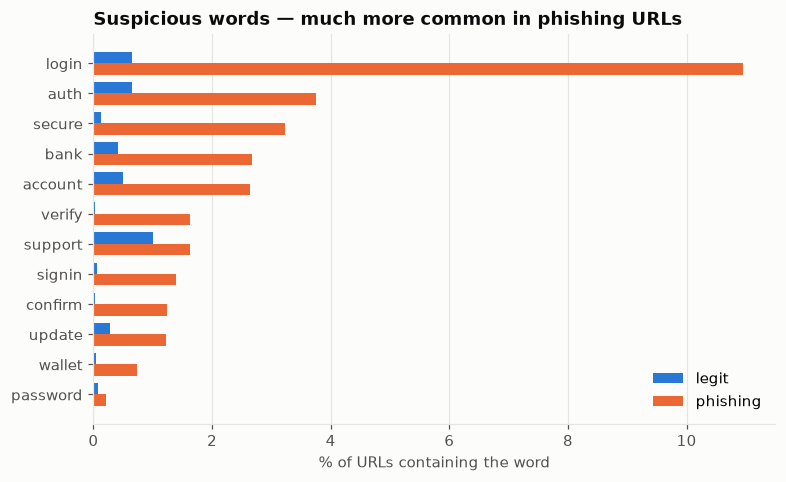

cls,legit,phishing
login,0.66,10.95
auth,0.64,3.76
secure,0.14,3.23
bank,0.42,2.66
account,0.50,2.64
verify,0.02,1.64
support,1.01,1.62
signin,0.06,1.38
confirm,0.02,1.24
update,0.28,1.22


In [5]:
WORDS = [
    "login",
    "signin",
    "verify",
    "account",
    "secure",
    "update",
    "confirm",
    "bank",
    "password",
    "wallet",
    "support",
    "auth",
]
lower = df["mi"].str.lower()
word_share = pd.DataFrame(
    {w: lower.str.contains(w, regex=False).groupby(df["cls"]).mean() * 100 for w in WORDS}
).T
word_share = word_share.sort_values("phishing")

fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(word_share))
ax.barh(y + h / 2, word_share["legit"], height=h, color=COLORS["legit"], label="legit")
ax.barh(y - h / 2, word_share["phishing"], height=h, color=COLORS["phishing"], label="phishing")
ax.set_yticks(y, word_share.index)
ax.set_xlabel("% of URLs containing the word")
ax.set_title("Suspicious words — much more common in phishing URLs")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "words")
plt.show()
word_share.iloc[::-1].round(2)

**Reading:** words like *login*, *verify*, *secure*, *account* appear far more often in phishing.
Supports `num_suspicious_words`. Note some legit pages also contain them (e.g. real login pages),
so this is a signal, not proof.

## 5. Structure: digits, hyphens, dots, subdomains, path depth

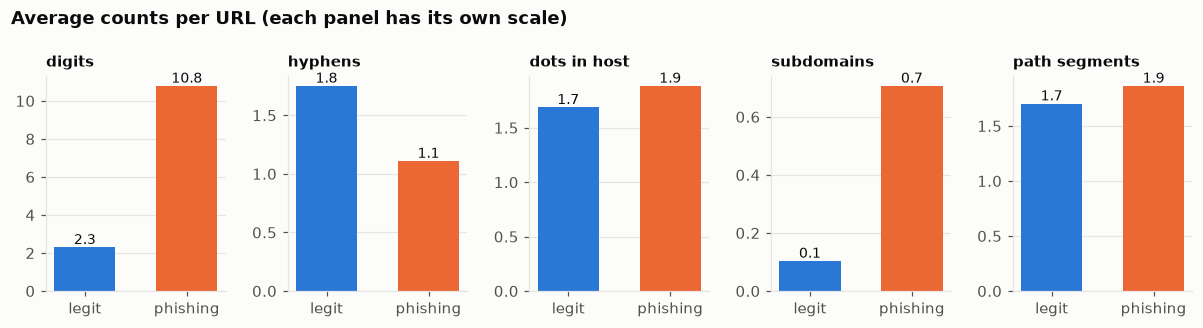

,digits,hyphens,dots_in_host,subdomains,path_segments
cls,,,,,
legit,2.30,1.75,1.69,0.10,1.70
phishing,10.78,1.11,1.88,0.71,1.86


In [6]:
df["digits"] = df["mi"].str.count(r"\d")
df["hyphens"] = df["mi"].str.count("-")
df["dots_in_host"] = df["host"].str.count(r"\.")
df["subdomains"] = df["host"].map(
    lambda h: len([p for p in _ext(h).subdomain.split(".") if p and p != "www"])
)
df["path_segments"] = df["mi"].map(lambda u: len([p for p in u.split("?")[0].split("/")[1:] if p]))

cols = ["digits", "hyphens", "dots_in_host", "subdomains", "path_segments"]
means = df.groupby("cls")[cols].mean()

fig, axes = plt.subplots(1, len(cols), figsize=(11, 3))
for ax, col in zip(axes, cols, strict=False):
    vals = means[col]
    ax.bar([0, 1], vals, color=[COLORS["legit"], COLORS["phishing"]], width=0.6)
    ax.set_xticks([0, 1], ["legit", "phishing"])
    ax.set_title(col.replace("_", " "), fontsize=10)
    for x, v in enumerate(vals):
        ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", color=TEXT, fontsize=9)
    ax.grid(axis="x", visible=False)
fig.suptitle(
    "Average counts per URL (each panel has its own scale)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=TEXT,
)
fig.tight_layout()
save(fig, "structure")
plt.show()
means.round(2)

**Reading:** phishing URLs carry about **5× more digits** (random tokens, IDs) and more subdomains
(`paypal.com.login.example.xyz`). **Surprise:** legit URLs have *more* hyphens — real sites use
readable slugs like `/creamy-pasta-recipes`. So a hyphen in the *path* is normal; a hyphen in the
*domain* (`secure-paypal-login.com`) is the suspicious kind. Feature idea for Phase 2: count
hyphens in the domain separately.

## 6. Rare but strong red flags

In [7]:
flags = (
    pd.DataFrame(
        {
            "IP address as host": df["host"].str.fullmatch(r"\d{1,3}(\.\d{1,3}){3}"),
            "'@' in URL": df["mi"].str.contains("@", regex=False),
            "punycode (xn--)": df["host"].str.contains("xn--", regex=False),
            "port number": df["url"].str.contains(r"^https?://[^/]+:\d+", regex=True),
            "%-encoding": df["mi"].str.contains(r"%[0-9a-fA-F]{2}", regex=True),
            "'//' inside path": df["mi"].str.contains("//", regex=False),
        }
    )
    .groupby(df["cls"])
    .mean()
    .T
    * 100
)
flags.round(2)

cls,legit,phishing
IP address as host,0.00,1.12
'@' in URL,0.02,1.95
punycode (xn--),0.14,0.11
port number,0.00,0.18
%-encoding,2.54,2.26
'//' inside path,0.14,0.72


**Reading:** IP hosts, `@` and `//` inside the path are rare but almost only in phishing —
rare-but-strong signals that tree models (LightGBM) use well. Punycode and %-encoding turn out to
be **equally common in both classes**, so they will probably add little. That is a useful result too.

## 7. Where is phishing hosted?

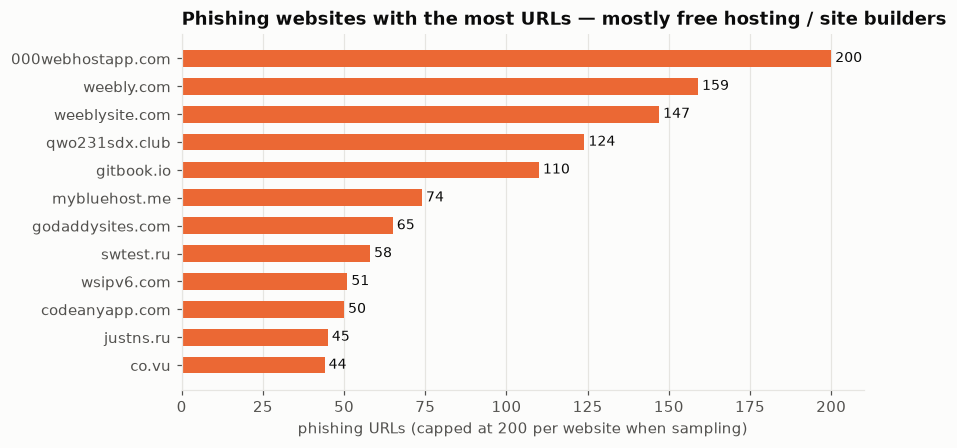

In [8]:
top_hosts = df.loc[df["cls"] == "phishing", "domain"].value_counts().head(12)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_hosts.index, top_hosts.values, color=COLORS["phishing"], height=0.6)
for i, v in enumerate(top_hosts.values):
    ax.text(v, i, f" {v}", va="center", color=TEXT, fontsize=9)
ax.set_xlabel("phishing URLs (capped at 200 per website when sampling)")
ax.set_title("Phishing websites with the most URLs — mostly free hosting / site builders")
ax.grid(axis="y", visible=False)
save(fig, "phishing_hosts")
plt.show()

**Reading:** attackers rely on free site builders and hosting (000webhostapp, weebly, gitbook,
godaddysites…). Their URLs can look clean (`something.weebly.com`), which is a known limitation of
URL-only detection. The 200-per-website cap kept any single host from dominating.

## 8. Brand impersonation

cls
legit        1.18
phishing    14.90
Name: % URLs mentioning a brand that is not their own domain, dtype: float64


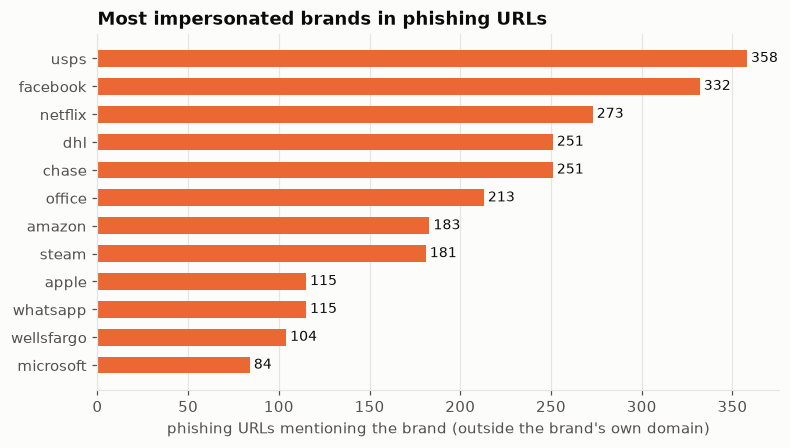

In [9]:
BRANDS = {
    "paypal": "paypal",
    "apple": "apple",
    "microsoft": "microsoft",
    "office": "office",
    "outlook": "outlook",
    "google": "google",
    "amazon": "amazon",
    "netflix": "netflix",
    "facebook": "facebook",
    "instagram": "instagram",
    "whatsapp": "whatsapp",
    "dhl": "dhl",
    "usps": "usps",
    "ebay": "ebay",
    "linkedin": "linkedin",
    "docusign": "docusign",
    "yahoo": "yahoo",
    "coinbase": "coinbase",
    "metamask": "metamask",
    "binance": "binance",
    "steam": "steam",
    "wellsfargo": "wellsfargo",
    "chase": "chase",
}


def brand_misuse(row):
    """Brand word appears in the URL, but the website is NOT that brand's own domain."""
    site = row["domain"].split(".")[0]
    return [b for b in BRANDS if b in row["mi"].lower() and site != b]


df["brands_misused"] = df.apply(brand_misuse, axis=1)
print(
    df.groupby("cls")["brands_misused"]
    .apply(lambda s: (s.str.len() > 0).mean() * 100)
    .round(2)
    .rename("% URLs mentioning a brand that is not their own domain")
)

counts = (
    df.loc[df["cls"] == "phishing", "brands_misused"]
    .explode()
    .dropna()
    .value_counts()
    .head(12)[::-1]
)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(counts.index, counts.values, color=COLORS["phishing"], height=0.6)
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v}", va="center", color=TEXT, fontsize=9)
ax.set_xlabel("phishing URLs mentioning the brand (outside the brand's own domain)")
ax.set_title("Most impersonated brands in phishing URLs")
ax.grid(axis="y", visible=False)
save(fig, "brands")
plt.show()

**Reading:** brand names appearing on a *different* website is a classic phishing trick
(`paypal.secure-login.xyz`). This supports features 21–22 (`brand_in_url_not_domain`,
`brand_lookalike`). Some legit hits exist too (e.g. a news site linking to `/apple-event`), so it
is a strong signal, not a rule.

## 9. Bias check (summary)

In [10]:
from urllib.parse import urlsplit

check = (
    pd.DataFrame(
        {
            "has path or query": df["url"].map(
                lambda u: urlsplit(u).path not in ("", "/") or bool(urlsplit(u).query)
            ),
            "uses https (hidden from models)": df["url"].str.startswith("https"),
            "starts with www (hidden from models)": df["url"].str.contains(
                r"^https?://www\.", regex=True
            ),
        }
    )
    .groupby(df["cls"])
    .mean()
    .T
    * 100
)
check.round(1)

cls,legit,phishing
has path or query,87.5,72.9
uses https (hidden from models),99.2,76.6
starts with www (hidden from models),50.8,8.9


## Conclusions

| Finding | Effect on the project |
|---|---|
| Both classes mostly have paths (legit ≈ 88 %, phishing ≈ 72 %) | The "long URL = phishing" shortcut is not available — the crawl did its job |
| https / www differ strongly between classes | Pure collection artefact → hidden from the models by `model_input()` |
| Length, digits, subdomains differ but overlap | Good *hints* — the model must combine several signals |
| Legit has *more* hyphens (path slugs) | Hyphens should be counted in the domain, not the whole URL |
| Default port `:443` appeared in 2.4 % of legit URLs | Collection artefact → fixed in `normalize_url()` (default ports removed) |
| Suspicious words, cheap TLDs, brand misuse lean strongly phishing | Our word / TLD / brand features should be among the most useful |
| IP host, `@`, punycode, `//` are rare but one-sided | Rare-but-strong flags — well suited to tree models |
| Phishing heavily uses free hosting | Known limitation of URL-only detection; mention in README |
| Legit = ~3.6k websites, phishing = ~15.5k websites | Must split train/test **by website** (Phase 3) |